In [ ]:
import pandas as pd
data = https://raw.githubusercontent.com/ritvikmath/Time-Series-Analysis/refs/heads/master/catfish.csv

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from datetime import timedelta
from pandas.plotting import register_matplotlib_converters
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.arima_model import ARIMA
register_matplotlib_converters()
from time import time

In [2]:
def parser(x):
  return datetime.strptime(x,'%Y-%m-%d')

In [14]:
cat_fish_sales = pd.read_csv('https://raw.githubusercontent.com/ritvikmath/Time-Series-Analysis/refs/heads/master/catfish.csv',date_parser=parser)
cat_fish_sales

<ipython-input-14-b34cab6077f9>:1: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  cat_fish_sales = pd.read_csv('https://raw.githubusercontent.com/ritvikmath/Time-Series-Analysis/refs/heads/master/catfish.csv',date_parser=parser)


,Date,Total
0,1986-1-01,9034
1,1986-2-01,9596
2,1986-3-01,10558
3,1986-4-01,9002
4,1986-5-01,9239
...,...,...
319,2012-8-01,14442
320,2012-9-01,13422
321,2012-10-01,13795
322,2012-11-01,13352


In [16]:

cat_fish_sales = cat_fish_sales.set_index('Date')
cat_fish_sales

,Total
Date,
1986-1-01,9034
1986-2-01,9596
1986-3-01,10558
1986-4-01,9002
1986-5-01,9239
...,...
2012-8-01,14442
2012-9-01,13422
2012-10-01,13795


In [17]:
lim_cat_fish_sales = cat_fish_sales['2000-1-01':'2004-1-01']

<Axes: xlabel='Date'>

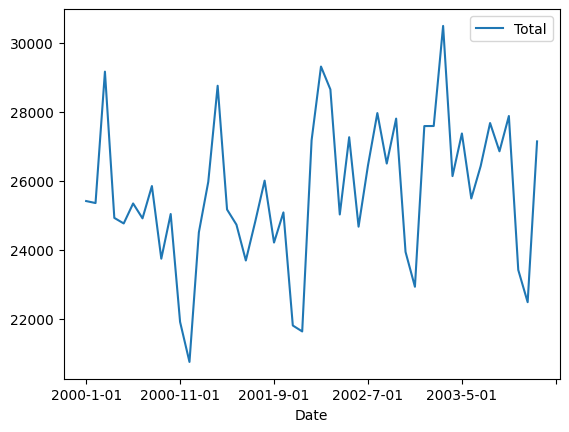

In [18]:
lim_cat_fish_sales.plot()

## ACF

In [34]:
first_diff = lim_cat_fish_sales.diff()[1:]

In [35]:
first_diff

,Total
Date,
2000-2-01,-58.0
2000-3-01,3807.0
2000-4-01,-4237.0
2000-5-01,-161.0
2000-6-01,579.0
2000-7-01,-431.0
2000-8-01,936.0
2000-9-01,-2104.0
2000-10-01,1293.0


<BarContainer object of 10 artists>

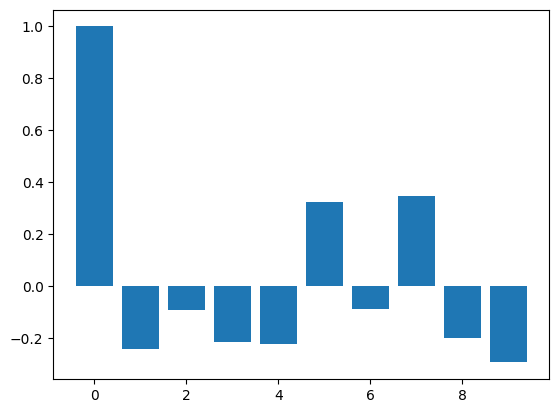

In [28]:
acf_vals = acf(first_diff)
num_lags = 10
plt.bar(range(num_lags),acf_vals[:num_lags])

## PACF

<BarContainer object of 10 artists>

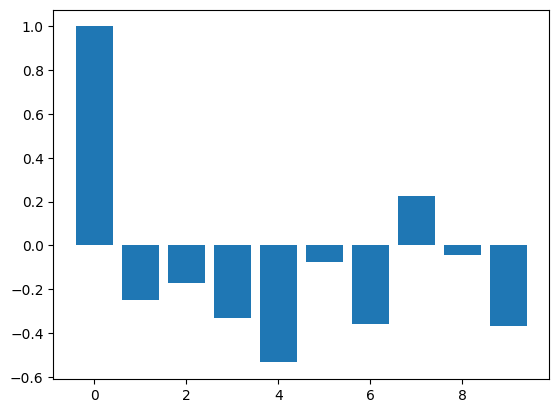

In [29]:
pacf_vals = pacf(first_diff)
num_lags = 10
plt.bar(range(num_lags),pacf_vals[:num_lags])

In [50]:
train_end = datetime(2003,7,1)
test_end = datetime(2004,1,1)

train_data = first_diff[:train_end]
test_data = first_diff[train_end + timedelta(days=1):test_end]

KeyError: datetime.datetime(2003, 7, 1, 0, 0)

In [51]:
# Calculate the split index
train_size = int(len(first_diff) * 0.8)  # 80% for training

# Split the data
train_data = first_diff[:train_size]
test_data = first_diff[train_size:]

In [62]:
model = ARMA(train_data,order=(4,1))
model_fit = model.fit()

NotImplementedError: 
statsmodels.tsa.arima_model.ARMA and statsmodels.tsa.arima_model.ARIMA have
been removed in favor of statsmodels.tsa.arima.model.ARIMA (note the .
between arima and model) and statsmodels.tsa.SARIMAX.

statsmodels.tsa.arima.model.ARIMA makes use of the statespace framework and
is both well tested and maintained. It also offers alternative specialized
parameter estimators.


In [64]:
from statsmodels.tsa.arima.model import ARIMA # Import the correct ARIMA class

# ... your other code ...

model = ARIMA(train_data, order=(4, 1,0)) # Use the updated ARIMA class
model_fit = model.fit()

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [65]:
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Total   No. Observations:                   38
Model:                 ARIMA(4, 1, 0)   Log Likelihood                -341.041
Date:                Mon, 03 Feb 2025   AIC                            692.083
Time:                        13:58:25   BIC                            700.137
Sample:                    02-01-2000   HQIC                           694.923
                         - 03-01-2003                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8710      0.150     -5.790      0.000      -1.166      -0.576
ar.L2         -0.6860      0.165     -4.166      0.000      -1.009      -0.363
ar.L3         -0.6162      0.194     -3.177      0.0

In [66]:
# get prediction start and end dates
pred_start_date = test_data.index[0]
pred_end_date = test_data.index[-1]

# make predictions
predictions = model_fit.predict(start=pred_start_date, end=pred_end_date)

In [67]:
#get the predictions and residuals
predictions = model_fit.predict(start=pred_start_date, end=pred_end_date)
residuals = test_data - predictions